In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.impute import KNNImputer
from scipy.stats import zscore

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
uploaded = files.upload()

file_name = next(iter(uploaded.keys()))

df = pd.read_csv("data.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Saving data.csv to data (1).csv
Dataset loaded successfully!
Dataset shape: (1200, 14)


,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


In [ ]:
# Display the first 5 rows
display(df.head())

# Display the last 5 rows
display(df.tail())

# Number of rows and columns
print("Shape:", df.shape)

# Column names and data types
df.info()

# Statistical summary
display(df.describe(include="all").T)

# Number of duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Number of missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
1195,ORD201195,2024-06-20,C21126,Desk,1,107.04,392 Main St,Credit Card,Cancelled,TRK38009181,6,FREESHIP,Google,107.04
1196,ORD201196,2024-03-04,C20095,Monitor,2,662.53,778 Main St,Online,Cancelled,TRK69207593,5,NaN,Facebook,1325.06
1197,ORD201197,2023-07-13,C79674,Tablet,2,436.84,275 Main St,Online,Delivered,TRK88039356,2,FREESHIP,Instagram,873.68
1198,ORD201198,2024-08-22,C64753,Chair,4,262.52,509 Main St,Debit Card,Cancelled,TRK71683331,4,WINTER15,Instagram,1050.08
1199,ORD201199,2023-06-11,C57502,Tablet,4,560.58,201 Main St,Gift Card,Returned,TRK51116746,6,SAVE10,Referral,2242.32


Shape: (1200, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          1200 non-null   object 
 1   Date             1200 non-null   object 
 2   CustomerID       1200 non-null   object 
 3   Product          1200 non-null   object 
 4   Quantity         1200 non-null   int64  
 5   UnitPrice        1200 non-null   float64
 6   ShippingAddress  1200 non-null   object 
 7   PaymentMethod    1200 non-null   object 
 8   OrderStatus      1200 non-null   object 
 9   TrackingNumber   1200 non-null   object 
 10  ItemsInCart      1200 non-null   int64  
 11  CouponCode       891 non-null    object 
 12  ReferralSource   1200 non-null   object 
 13  TotalPrice       1200 non-null   float64
dtypes: float64(2), int64(2), object(10)
memory usage: 131.4+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
OrderID,1200,1200,ORD201183,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,1200,671,2023-08-20,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CustomerID,1200,1189,C46651,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product,1200,7,Printer,181,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,1200.0,NaN,NaN,NaN,2.945833,1.407557,1.0,2.0,3.0,4.0,5.0
UnitPrice,1200.0,NaN,NaN,NaN,356.41275,197.177146,11.39,186.0625,364.21,521.57,699.93
ShippingAddress,1200,655,533 Main St,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PaymentMethod,1200,5,Online,258,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OrderStatus,1200,5,Cancelled,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TrackingNumber,1200,1200,TRK83653396,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Duplicate rows: 0

Missing values:
OrderID              0
Date                 0
CustomerID           0
Product              0
Quantity             0
UnitPrice            0
ShippingAddress      0
PaymentMethod        0
OrderStatus          0
TrackingNumber       0
ItemsInCart          0
CouponCode         309
ReferralSource       0
TotalPrice           0
dtype: int64


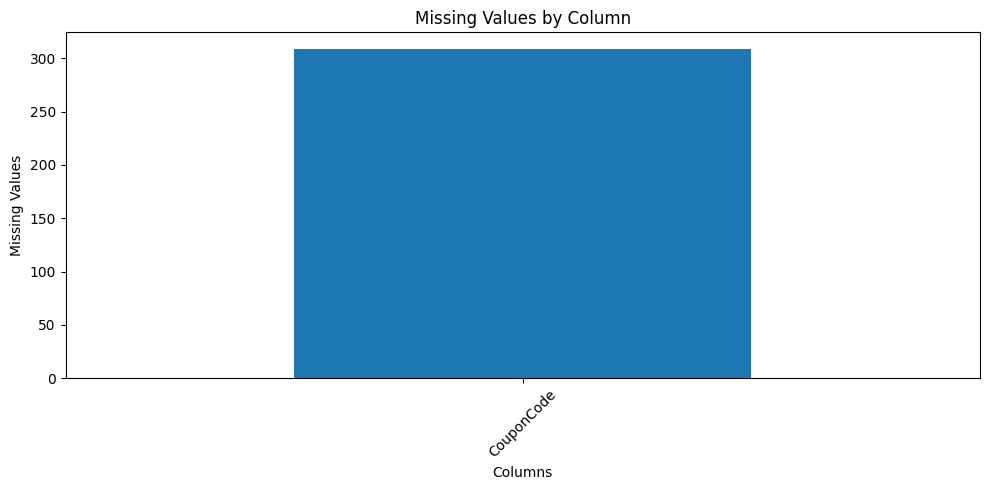

In [ ]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing) > 0:
    missing.plot(kind="bar", figsize=(10, 5))
    plt.title("Missing Values by Column")
    plt.xlabel("Columns")
    plt.ylabel("Missing Values")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

In [ ]:
before = len(df)

df = df.drop_duplicates().copy()

after = len(df)

print("Duplicate rows removed:", before - after)
print("Remaining rows:", after)

Duplicate rows removed: 0
Remaining rows: 1200


In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

categorical_cols = df.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

print("Numerical columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

Numerical columns: ['Quantity', 'UnitPrice', 'ItemsInCart', 'TotalPrice']
Categorical columns: ['OrderID', 'Date', 'CustomerID', 'Product', 'ShippingAddress', 'PaymentMethod', 'OrderStatus', 'TrackingNumber', 'CouponCode', 'ReferralSource']


In [ ]:
# Keep a copy of the data before imputation
df_imputation_test = df.copy()

# Mean imputation
mean_data = df_imputation_test.copy()

for col in numeric_cols:
    if mean_data[col].notna().any():
        mean_data[col] = mean_data[col].fillna(
            mean_data[col].mean()
        )

# Median imputation
median_data = df_imputation_test.copy()

for col in numeric_cols:
    if median_data[col].notna().any():
        median_data[col] = median_data[col].fillna(
            median_data[col].median()
        )

# KNN imputation
knn_data = df_imputation_test.copy()

if numeric_cols:
    knn_imputer = KNNImputer(n_neighbors=5)
    knn_values = knn_imputer.fit_transform(
        knn_data[numeric_cols]
    )

    knn_data[numeric_cols] = pd.DataFrame(
        knn_values,
        columns=numeric_cols,
        index=knn_data.index
    )

print("Mean, Median and KNN imputation comparisons completed.")

Mean, Median and KNN imputation comparisons completed.


In [ ]:
df_clean = df.copy()

for col in numeric_cols:
    if df_clean[col].notna().any():
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].median()
        )

for col in categorical_cols:
    if df_clean[col].notna().any():
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].mode().iloc[0]
        )

print("Missing values handled.")
print(df_clean.isnull().sum())

Missing values handled.
OrderID            0
Date               0
CustomerID         0
Product            0
Quantity           0
UnitPrice          0
ShippingAddress    0
PaymentMethod      0
OrderStatus        0
TrackingNumber     0
ItemsInCart        0
CouponCode         0
ReferralSource     0
TotalPrice         0
dtype: int64


In [ ]:
empty_cols = df_clean.columns[df_clean.isnull().all()].tolist()

print("Completely empty columns:", empty_cols)

df_clean = df_clean.drop(columns=empty_cols)

# Recalculate column types after removing empty columns
numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()

categorical_cols = df_clean.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

print("Remaining shape:", df_clean.shape)

Completely empty columns: []
Remaining shape: (1200, 14)


In [ ]:
outlier_counts = {}

for col in numeric_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = (
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ).sum()

    outlier_counts[col] = count

print("Outlier counts:")
print(pd.Series(outlier_counts))

Outlier counts:
Quantity       0
UnitPrice      0
ItemsInCart    0
TotalPrice     8
dtype: int64


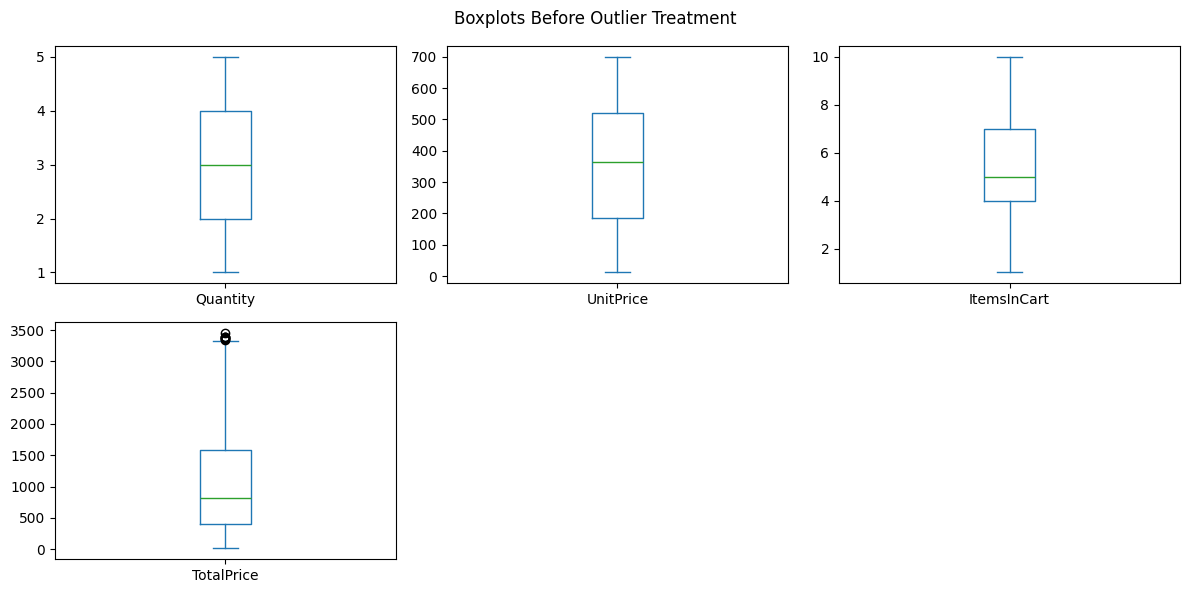

In [ ]:
if numeric_cols:
    df_clean[numeric_cols].plot(
        kind="box",
        subplots=True,
        layout=(-1, 3),
        figsize=(12, max(4, len(numeric_cols) * 1.5)),
        sharex=False,
        sharey=False
    )

    plt.suptitle("Boxplots Before Outlier Treatment")
    plt.tight_layout()
    plt.show()

In [ ]:
df_outlier_treated = df_clean.copy()

iqr_bounds = {}

for col in numeric_cols:
    q1 = df_outlier_treated[col].quantile(0.25)
    q3 = df_outlier_treated[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    iqr_bounds[col] = (lower, upper)

    df_outlier_treated[col] = df_outlier_treated[col].clip(
        lower=lower,
        upper=upper
    )

print("IQR outlier capping completed.")
print("Rows preserved:", len(df_outlier_treated))

IQR outlier capping completed.
Rows preserved: 1200


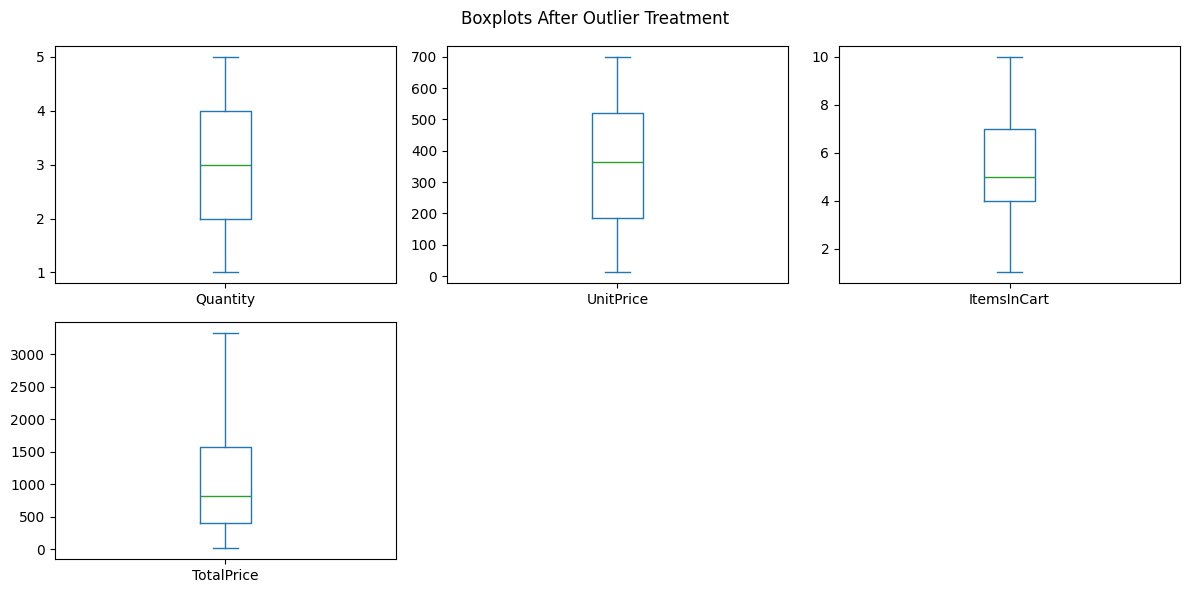

In [ ]:
if numeric_cols:
    df_outlier_treated[numeric_cols].plot(
        kind="box",
        subplots=True,
        layout=(-1, 3),
        figsize=(12, max(4, len(numeric_cols) * 1.5)),
        sharex=False,
        sharey=False
    )

    plt.suptitle("Boxplots After Outlier Treatment")
    plt.tight_layout()
    plt.show()

In [ ]:
for col in numeric_cols:
    std = df_clean[col].std()

    if pd.notna(std) and std > 0:
        z_scores = (
            df_clean[col] - df_clean[col].mean()
        ) / std

        print(
            f"{col}:",
            int((z_scores.abs() > 3).sum()),
            "potential Z-score outliers"
        )

Quantity: 0 potential Z-score outliers
UnitPrice: 0 potential Z-score outliers
ItemsInCart: 0 potential Z-score outliers
TotalPrice: 0 potential Z-score outliers


In [ ]:
# Enter your target column name if your dataset has one.
# Example: TARGET_COLUMN = "math score"
TARGET_COLUMN = None

feature_cols = [
    col for col in numeric_cols
    if col != TARGET_COLUMN
]

if not feature_cols:
    raise ValueError(
        "At least one numeric feature column is required."
    )

df_features = df_outlier_treated.copy()

# Feature 1: Mean of the numerical input features
df_features["feature_row_mean"] = (
    df_features[feature_cols].mean(axis=1)
)

# Feature 2: Standard deviation across the input features
df_features["feature_row_std"] = (
    df_features[feature_cols].std(axis=1, ddof=0)
)

# Feature 3: Difference between two numerical input features
if len(feature_cols) >= 2:
    first_col = feature_cols[0]
    second_col = feature_cols[1]

    df_features["feature_difference"] = (
        df_features[first_col] - df_features[second_col]
    )
else:
    # Fallback when only one numerical feature exists
    col = feature_cols[0]

    df_features["feature_squared"] = df_features[col] ** 2
    df_features["feature_absolute"] = df_features[col].abs()

print("Feature engineering completed.")

display(df_features.head())

print(
    "New features:",
    [
        col for col in df_features.columns
        if col.startswith("feature_")
    ]
)

Feature engineering completed.


,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice,feature_row_mean,feature_row_std,feature_difference
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10,858.9300,1174.182462,-565.62
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70,114.7625,124.363768,-149.35
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40,829.2700,1132.893871,-545.68
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19,138.0950,135.102402,-272.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04,785.5125,1023.970860,-622.01


New features: ['feature_row_mean', 'feature_row_std', 'feature_difference']


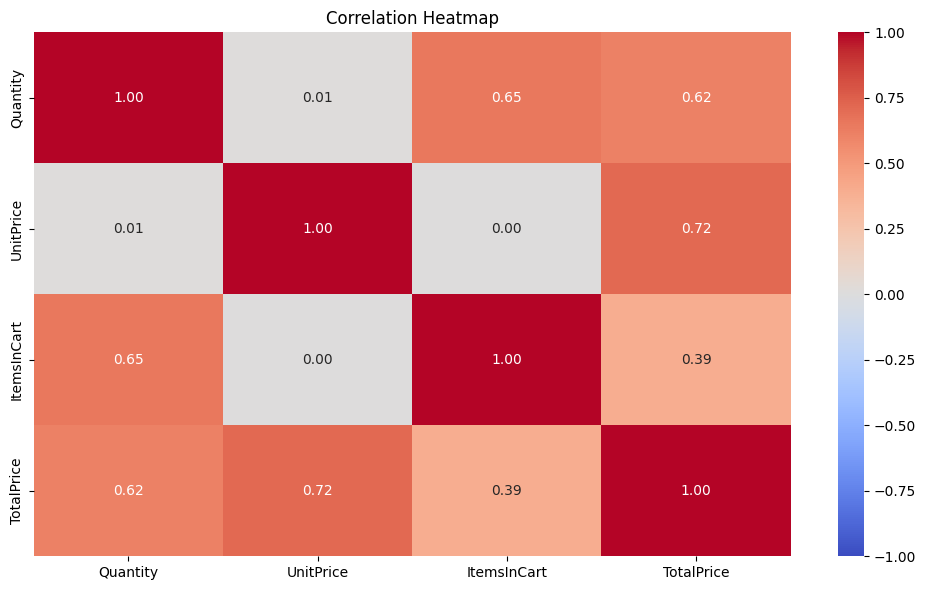

In [ ]:
if len(feature_cols) >= 2:
    plt.figure(figsize=(10, 6))

    sns.heatmap(
        df_features[feature_cols].corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        vmin=-1,
        vmax=1
    )

    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()
else:
    print("At least two numerical features are needed for a heatmap.")

In [ ]:
df_ml = df_features.copy()

# Recalculate categorical columns after cleaning
categorical_cols = df_ml.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

# Do not encode the target as an input feature
categorical_features = [
    col for col in categorical_cols
    if col != TARGET_COLUMN
]

df_ml = pd.get_dummies(
    df_ml,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

print("Categorical encoding completed.")
print("ML-ready dataset shape:", df_ml.shape)

display(df_ml.head())

Categorical encoding completed.
ML-ready dataset shape: (1200, 4937)


,Quantity,UnitPrice,ItemsInCart,TotalPrice,feature_row_mean,feature_row_std,feature_difference,OrderID_ORD200001,OrderID_ORD200002,OrderID_ORD200003,...,TrackingNumber_TRK99820544,TrackingNumber_TRK99880231,TrackingNumber_TRK99938245,TrackingNumber_TRK99985340,CouponCode_SAVE10,CouponCode_WINTER15,ReferralSource_Facebook,ReferralSource_Google,ReferralSource_Instagram,ReferralSource_Referral
0,5,570.62,7,2853.10,858.9300,1174.182462,-565.62,0,0,0,...,0,0,0,0,1,0,0,0,1,0
1,2,151.35,3,302.70,114.7625,124.363768,-149.35,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,5,550.68,8,2753.40,829.2700,1132.893871,-545.68,0,1,0,...,0,0,0,0,0,0,0,0,0,0
3,1,273.19,5,273.19,138.0950,135.102402,-272.19,0,0,1,...,0,0,0,0,1,0,1,0,0,0
4,4,626.01,8,2504.04,785.5125,1023.970860,-622.01,0,0,0,...,0,0,0,0,1,0,0,0,0,0


In [ ]:
print("Final dataset shape:", df_features.shape)

print("\nMissing values remaining:")
print(df_features.isnull().sum())

print("\nDuplicate rows remaining:")
print(df_features.duplicated().sum())

new_features = [
    col for col in df_features.columns
    if col.startswith("feature_")
]

print("\nNumber of new features:", len(new_features))
print("New feature names:", new_features)

assert len(new_features) >= 3, (
    "The project requires at least 3 new features."
)

assert df_features.isnull().sum().sum() == 0, (
    "Some missing values remain. Check the affected columns."
)

print("\nValidation completed.")

Final dataset shape: (1200, 17)

Missing values remaining:
OrderID               0
Date                  0
CustomerID            0
Product               0
Quantity              0
UnitPrice             0
ShippingAddress       0
PaymentMethod         0
OrderStatus           0
TrackingNumber        0
ItemsInCart           0
CouponCode            0
ReferralSource        0
TotalPrice            0
feature_row_mean      0
feature_row_std       0
feature_difference    0
dtype: int64

Duplicate rows remaining:
0

Number of new features: 3
New feature names: ['feature_row_mean', 'feature_row_std', 'feature_difference']

Validation completed.


In [ ]:
# Save the cleaned dataset with engineered features
df_features.to_csv(
    "DecodeLabs_Cleaned_Featured_Dataset.csv",
    index=False
)

# Save the encoded dataset for machine learning
df_ml.to_csv(
    "DecodeLabs_ML_Ready_Dataset.csv",
    index=False
)

print("Both datasets saved successfully!")

Both datasets saved successfully!


In [29]:
files.download("DecodeLabs_Cleaned_Featured_Dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
files.download("DecodeLabs_ML_Ready_Dataset.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>